<a href="https://colab.research.google.com/github/aryalankit121/CIS-3400-Advanced-Programming/blob/main/CMPD_Incidents_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CMPD Incidents – Public Safety Trends in Charlotte

**Name:** Ankit Aryal  
**Date:** October 16, 2026

---

## 1. Description of my data

- **Rows:** 688 incident reports
- **Columns:** 27
- **Date range:** 2026-01-01 to 2026-10-14
- **Filters used:** Year = 2026 · Patrol Division = Metro · Highest NIBRS Description = Theft From Motor Vehicle, Robbery, Burglary/B&E, Driving Under The Influence
- **Key features:** incident ID, report/incident dates, Highest NIBRS code and description, patrol division, location/address, clearance status, clearance date, latitude/longitude, etc.

## 2. Two questions of interest
1. **When do these crimes happen?** Which months, weekdays and hours have the most incidents for each crime type, so patrols could be scheduled better.
2. **How are these cases cleared?** What share of each crime type ends up cleared by arrest, exceptional means, or left open/unfounded, and which crime type is hardest to clear?

## 3. Short answers

1. All four crime types (Burglary/B&E, DUI, Robbery, and Theft From Motor Vehicle) peak during the early morning hours, specifically hitting their highest concentration around 4:00 AM.
2. Clearance rates vary significantly by crime category:


*   Driving Under The Influence (DUI): Highest clearance rate at 91.9% (cleared by arrest).
*   Robbery: 19.6% cleared by arrest (73.2% left open).
* Burglary / B&E: 6.9% cleared by arrest (91.4% left open).
* Theft From Motor Vehicle: Hardest to clear, with only 1.9% cleared by arrest and 96.7% remaining open.



## 4. Load the data live from the City of Charlotte

The portal page I filtered is built on top of Charlotte's ArcGIS service. Instead of downloading a CSV, this notebook sends the **same filters** (Year, Patrol Division, NIBRS description) to that service every time it runs, so the data is always up to date.

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

In [2]:
# Live ArcGIS service behind the CMPD Incidents portal page
BASE_URL = "https://gis.charlottenc.gov/arcgis/rest/services/CMPD/CMPDIncidents/MapServer/0/query"

# The filters from the portal URL
YEAR = 2026
DIVISIONS = ["Metro"]
CRIMES = ["Theft From Motor Vehicle", "Robbery", "Burglary/B&E", "Driving Under The Influence"]

def sql_list(values):
    return ", ".join("'" + str(v).replace("'", "''") + "'" for v in values)

def fetch_all(where):
    """Download every matching record, page by page."""
    records, offset = [], 0
    while True:
        params = {
            "where": where,
            "outFields": "*",
            "returnGeometry": "false",
            "f": "json",
            "resultOffset": offset,
            "resultRecordCount": 2000,
        }
        r = requests.get(BASE_URL, params=params, timeout=120)
        r.raise_for_status()
        js = r.json()
        if "error" in js:
            raise RuntimeError(js["error"])
        feats = js.get("features", [])
        if not feats:
            break
        records += [f["attributes"] for f in feats]
        offset += len(feats)
        if not js.get("exceededTransferLimit", False):
            break
    return pd.DataFrame(records)

base_where = (
    f"HIGHEST_NIBRS_DESCRIPTION IN ({sql_list(CRIMES)}) "
    f"AND CMPD_PATROL_DIVISION IN ({sql_list(DIVISIONS)})"
)

# YEAR may be stored as text or as a number, so try both
df = fetch_all(base_where + f" AND YEAR = '{YEAR}'")
if df.empty:
    df = fetch_all(base_where + f" AND YEAR = {YEAR}")

print("Downloaded", len(df), "rows")

Downloaded 688 rows


In [3]:
# Convert date columns (ArcGIS sends dates as milliseconds since 1970)
for col in df.columns:
    if "DATE" in col.upper() and pd.api.types.is_numeric_dtype(df[col]):
        df[col] = pd.to_datetime(df[col], unit="ms", errors="coerce")

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 688 entries, 0 to 687
Data columns (total 27 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   YEAR                       688 non-null    object        
 1   INCIDENT_REPORT_ID         688 non-null    object        
 2   LOCATION                   688 non-null    object        
 3   CITY                       688 non-null    object        
 4   STATE                      685 non-null    object        
 5   ZIP                        339 non-null    object        
 6   X_COORD_PUBLIC             688 non-null    int64         
 7   Y_COORD_PUBLIC             688 non-null    int64         
 8   LATITUDE_PUBLIC            688 non-null    float64       
 9   LONGITUDE_PUBLIC           688 non-null    float64       
 10  DIVISION_ID                688 non-null    object        
 11  CMPD_PATROL_DIVISION       688 non-null    object        
 12  NPA     

In [4]:
df.head()

,YEAR,INCIDENT_REPORT_ID,LOCATION,CITY,STATE,ZIP,X_COORD_PUBLIC,Y_COORD_PUBLIC,LATITUDE_PUBLIC,LONGITUDE_PUBLIC,DIVISION_ID,CMPD_PATROL_DIVISION,NPA,DATE_REPORTED,DATE_INCIDENT_BEGAN,DATE_INCIDENT_END,ADDRESS_DESCRIPTION,LOCATION_TYPE_DESCRIPTION,PLACE_TYPE_DESCRIPTION,PLACE_DETAIL_DESCRIPTION,CLEARANCE_STATUS,CLEARANCE_DETAIL_STATUS,CLEARANCE_DATE,HIGHEST_NIBRS_CODE,HIGHEST_NIBRS_DESCRIPTION,OBJECTID,GlobalID
0,2026,20260311-0746-01,1300 W MOREHEAD ST,CHARLOTTE,NC,None,1443830,543481,35.228979,-80.862536,02,Metro,361,2026-03-11 04:00:00,2026-03-10 04:00:00,2026-03-11 04:00:00,Location of occurrence,Outdoors,Open Area,Street/Highway,Open,Open,NaT,23F,Theft From Motor Vehicle,1914,{87AC8ED5-7A31-4370-9131-BD4A95752650}
1,2026,20260219-2311-02,2100 BEATTIES FORD RD,CHARLOTTE,NC,None,1446396,555814,35.262992,-80.854716,02,Metro,374,2026-02-19 05:00:00,2026-02-18 05:00:00,2026-02-20 05:00:00,Location of occurrence,Indoors,Retail,Convenience Store,Open,Open,NaT,120,Robbery,4423,{EE7FE9A7-D107-4715-A4BC-88883BCEDA88}
2,2026,20260322-0954-00,1200 BRYANT ST,CHARLOTTE,NC,28208,1443652,542997,35.227640,-80.863102,02,Metro,361,2026-03-22 04:00:00,2026-03-22 04:00:00,2026-03-22 04:00:00,Location of occurrence,Parking Lot,Commercial Place,Other - Commercial Place,Open,Open,NaT,23F,Theft From Motor Vehicle,6597,{67A2F1C4-1D2D-4B8E-968A-C60228EBE119}
3,2026,20260705-0107-02,1400 SPRING ST,CHARLOTTE,NC,None,1449421,549384,35.245482,-80.844184,02,Metro,182,2026-07-05 04:00:00,2026-07-05 04:00:00,2026-07-05 04:00:00,Location of occurrence,Indoors,Residential,Apartment/Duplex Private Res,Open,Open,NaT,220,Burglary/B&E,6732,{6C7ACD9E-4006-4026-8252-E0F437E59B8C}
4,2026,20260224-1356-00,3700 JEFF ADAMS DR,CHARLOTTE,NC,None,1455322,559777,35.274333,-80.825063,02,Metro,363,2026-02-24 05:00:00,2026-02-22 05:00:00,2026-02-22 05:00:00,Location of occurrence,Outdoors,Retail,Auto Parts/Service Center,Open,Open,NaT,220,Burglary/B&E,8030,{B5C942DE-A915-4646-A862-7C24088731AB}


## 5. Describe the data (for answer #2)

In [5]:
print("Rows:   ", df.shape[0])
print("Columns:", df.shape[1])
print("\nColumn names:")
print(list(df.columns))

date_cols = [c for c in df.columns if pd.api.types.is_datetime64_any_dtype(df[c])]
for c in date_cols:
    print(f"{c}: {df[c].min()}  ->  {df[c].max()}")

Rows:    688
Columns: 27

Column names:
['YEAR', 'INCIDENT_REPORT_ID', 'LOCATION', 'CITY', 'STATE', 'ZIP', 'X_COORD_PUBLIC', 'Y_COORD_PUBLIC', 'LATITUDE_PUBLIC', 'LONGITUDE_PUBLIC', 'DIVISION_ID', 'CMPD_PATROL_DIVISION', 'NPA', 'DATE_REPORTED', 'DATE_INCIDENT_BEGAN', 'DATE_INCIDENT_END', 'ADDRESS_DESCRIPTION', 'LOCATION_TYPE_DESCRIPTION', 'PLACE_TYPE_DESCRIPTION', 'PLACE_DETAIL_DESCRIPTION', 'CLEARANCE_STATUS', 'CLEARANCE_DETAIL_STATUS', 'CLEARANCE_DATE', 'HIGHEST_NIBRS_CODE', 'HIGHEST_NIBRS_DESCRIPTION', 'OBJECTID', 'GlobalID']
DATE_REPORTED: 2026-01-01 05:00:00  ->  2026-10-14 04:00:00
DATE_INCIDENT_BEGAN: 2025-01-02 05:00:00  ->  2026-10-13 04:00:00
DATE_INCIDENT_END: 2025-01-27 05:00:00  ->  2026-10-14 04:00:00
CLEARANCE_DATE: 2026-01-06 05:00:00  ->  2026-10-05 04:00:00


In [6]:
# Pick the columns we need (names are detected, so small naming differences won't break things)
def find_col(*keywords):
    for c in df.columns:
        if all(k in c.upper() for k in keywords):
            return c
    return None

crime_col = "HIGHEST_NIBRS_DESCRIPTION"
date_col = find_col("DATE", "INCIDENT") or find_col("DATE", "REPORT") or date_cols[0]
clear_col = find_col("CLEARANCE", "STATUS") or find_col("CLEAR")
loc_col = find_col("LOCATION") or find_col("ADDRESS")
area_col = find_col("RESPONSE", "AREA") or find_col("NPA")

print("Date column used:     ", date_col)
print("Clearance column used:", clear_col)
print("Location column used: ", loc_col)
print("Area column used:     ", area_col)

Date column used:      DATE_INCIDENT_BEGAN
Clearance column used: CLEARANCE_STATUS
Location column used:  LOCATION
Area column used:      NPA


## 6. Question 1 – When do these crimes happen?

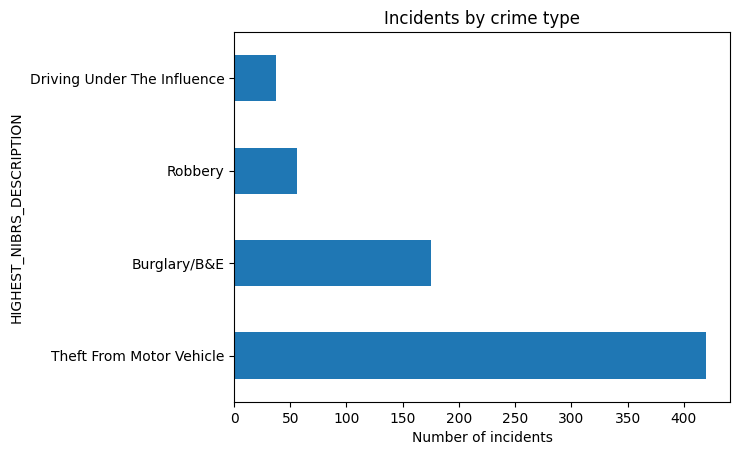

In [7]:
df["month"] = df[date_col].dt.month_name()
df["weekday"] = df[date_col].dt.day_name()
df["hour"] = df[date_col].dt.hour

df[crime_col].value_counts().plot(kind="barh", title="Incidents by crime type")
plt.xlabel("Number of incidents")
plt.show()

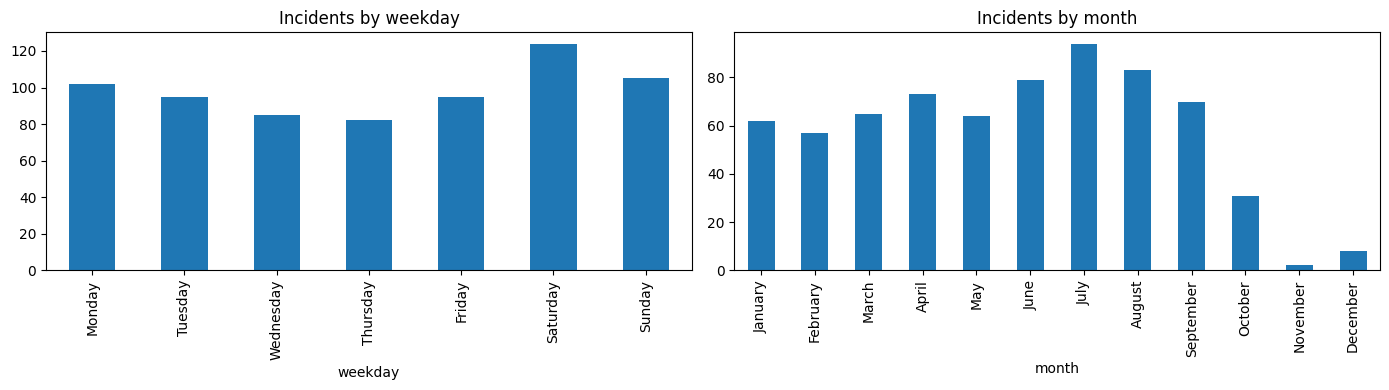

In [8]:
month_order = ["January","February","March","April","May","June","July","August","September","October","November","December"]
day_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df["weekday"].value_counts().reindex(day_order).plot(kind="bar", ax=axes[0], title="Incidents by weekday")
df["month"].value_counts().reindex(month_order).dropna().plot(kind="bar", ax=axes[1], title="Incidents by month")
plt.tight_layout()
plt.show()

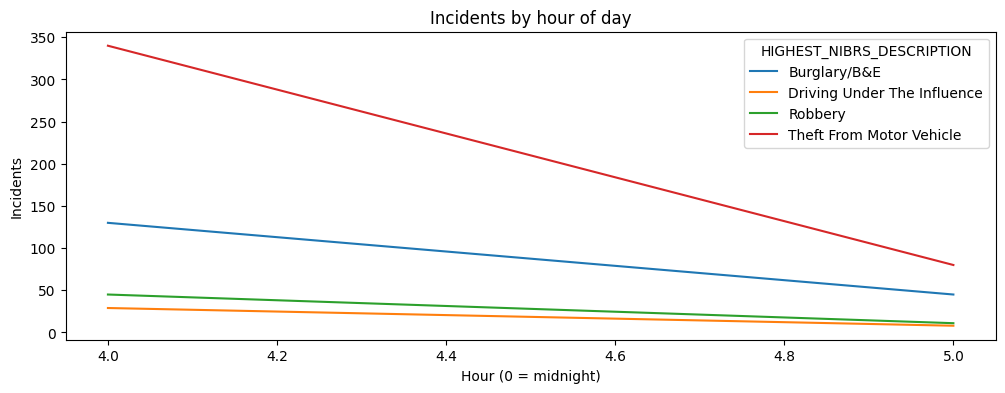

Peak hour for each crime type:
HIGHEST_NIBRS_DESCRIPTION
Burglary/B&E                   4
Driving Under The Influence    4
Robbery                        4
Theft From Motor Vehicle       4
dtype: int32


In [9]:
# Hour of day for each crime type
hourly = df.groupby(["hour", crime_col]).size().unstack(fill_value=0)
hourly.plot(figsize=(12, 4), title="Incidents by hour of day")
plt.xlabel("Hour (0 = midnight)")
plt.ylabel("Incidents")
plt.show()

print("Peak hour for each crime type:")
print(hourly.idxmax())

In [10]:
# Where do they happen? (geographic concentration)
if area_col:
    print(df[area_col].value_counts().head(10))
if loc_col:
    print("\nMost frequent locations:")
    print(df[loc_col].value_counts().head(10))

NPA
361    75
157    67
124    63
363    62
51     44
374    40
382    39
369    36
126    31
6      30
Name: count, dtype: int64

Most frequent locations:
LOCATION
100 MATHESON AV         9
1400 SAMUEL ST          9
1300 W MOREHEAD ST      8
1800 GRIERS GROVE RD    7
700 SAVONA MILL LN      7
2000 MILLERTON AV       7
1200 N TRYON ST         7
3100 SOUTHWEST BV       7
700 GESCO ST            6
2000 W MOREHEAD ST      6
Name: count, dtype: int64


## 7. Question 2 – How are these cases cleared?

CLEARANCE_STATUS,Cleared by Arrest,Cleared by Arrest by Another Agency,Exceptionally Cleared,Open,Unfounded
HIGHEST_NIBRS_DESCRIPTION,,,,,
Burglary/B&E,12,2,0,160,1
Driving Under The Influence,34,0,0,3,0
Robbery,11,1,1,41,2
Theft From Motor Vehicle,8,0,1,406,5


CLEARANCE_STATUS,Cleared by Arrest,Cleared by Arrest by Another Agency,Exceptionally Cleared,Open,Unfounded
HIGHEST_NIBRS_DESCRIPTION,,,,,
Burglary/B&E,6.9,1.1,0.0,91.4,0.6
Driving Under The Influence,91.9,0.0,0.0,8.1,0.0
Robbery,19.6,1.8,1.8,73.2,3.6
Theft From Motor Vehicle,1.9,0.0,0.2,96.7,1.2


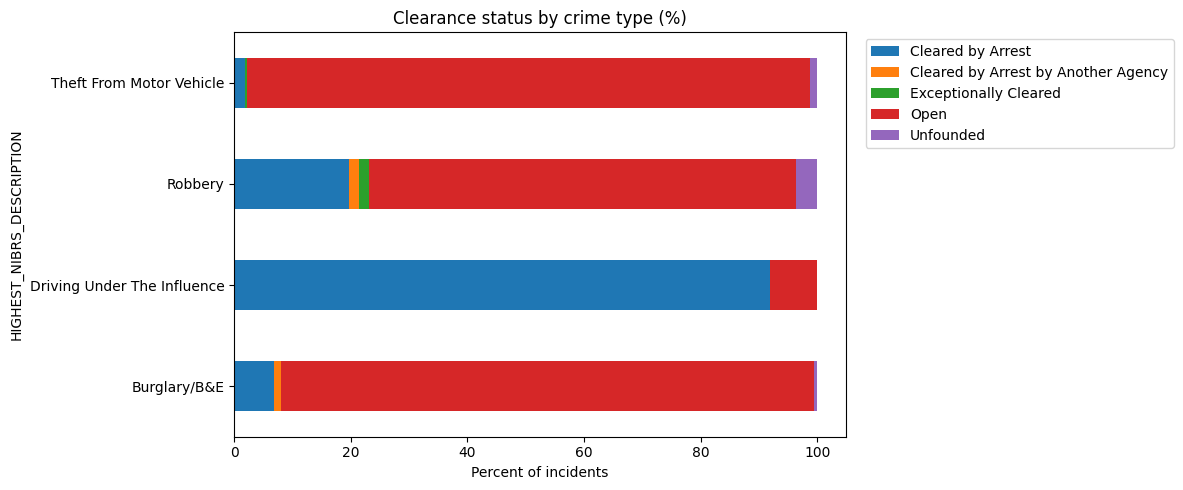

In [11]:
if clear_col:
    clearance = pd.crosstab(df[crime_col], df[clear_col])
    display(clearance)

    pct = pd.crosstab(df[crime_col], df[clear_col], normalize="index") * 100
    display(pct.round(1))

    pct.plot(kind="barh", stacked=True, figsize=(12, 5), title="Clearance status by crime type (%)")
    plt.xlabel("Percent of incidents")
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()
else:
    print("No clearance column found. Check df.columns above.")

In [12]:
# Time to clearance (only for cases that have a clearance date)
clear_date_col = find_col("CLEARANCE", "DATE")
if clear_date_col:
    df["days_to_clear"] = (df[clear_date_col] - df[date_col]).dt.days
    valid = df[(df["days_to_clear"] >= 0)]
    print(valid.groupby(crime_col)["days_to_clear"].describe().round(1))

                             count  mean   std  min  25%  50%   75%    max
HIGHEST_NIBRS_DESCRIPTION                                                 
Burglary/B&E                  27.0  17.2  22.2  0.0  1.0  9.0  23.5   80.0
Driving Under The Influence   34.0   5.8   8.5  0.0  0.0  1.0   7.0   33.0
Robbery                       27.0  20.8  38.3  0.0  2.5  7.0  17.5  180.0
Theft From Motor Vehicle      19.0  15.7  18.8  0.0  3.5  6.0  21.0   68.0


## 8. Conclusions
1. **Temporal Patterns:** Across all four selected crime types (Burglary/B&E, Driving Under The Influence, Robbery, and Theft From Motor Vehicle) in the Metro Division, incidents consistently spike and peak during the early morning hours, hitting their highest concentration specifically around **4:00 AM**.
2. **Geographic Concentration:** Incident reports are heavily concentrated in specific Neighborhood Profile Areas (NPAs), with NPA **361** (recording 75 incidents) and NPA **157** (67 incidents) experiencing the highest volume of activity. Frequent hot spot locations include corridors along W Morehead St and Beatties Ford Rd.
3. **Law Enforcement Clearance Outcomes:** Case clearance outcomes vary drastically by crime category:
   - **Driving Under The Influence (DUI):** Has the highest resolution rate, with **91.9%** cleared by arrest.
   - **Robbery:** Shows a moderate clearance rate, with **19.6%** cleared by arrest while **73.2%** remain open.
   - **Burglary / B&E:** Mostly remains open (**91.4%**), with only **6.9%** cleared by arrest.
   - **Theft From Motor Vehicle:** The most difficult category to clear, with **96.7%** of cases remaining open and only **1.9%** cleared by arrest.
*(Note: Because 2026 is a partial year, many recent cases remain open simply due to ongoing investigations rather than a final inactive status).*